# 01b - Train + evaluate MobileNetV3-Large
Self-contained: run the cells top to bottom (GPU runtime). Needs `data_v3.tar` on Drive from notebook 00.
Same split, learning rate, epochs, optimizer, schedule and augmentation as every other model (see `config.py`); only the architecture differs.
Results are saved to `MyDrive/plant-disease-v3/results/mobilenetv3_large/`.

In [ ]:
MODEL = "mobilenetv3_large"
from google.colab import drive; drive.mount("/content/drive")
import subprocess, sys, os
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "scikit-learn", "scipy", "tabulate"], check=True)
os.makedirs("/content/plant_pipeline", exist_ok=True); os.makedirs("/content/data_v3", exist_ok=True)

Mounted at /content/drive


In [ ]:
# ---- code bundle: all pipeline .py files (config, build_dataset, train, evaluate, report, compare, predict ...) ----
# Writing them here guarantees this notebook never runs a stale or half-patched copy from Drive. Readable copies: 00b notebook / plant_pipeline.zip.
import base64, io, zipfile, os, shutil
B64 = (
    "..."
)
os.makedirs("/content/plant_pipeline", exist_ok=True)
zipfile.ZipFile(io.BytesIO(base64.b64decode(B64))).extractall("/content/plant_pipeline")
os.makedirs("/content/drive/MyDrive/plant-disease-v3/code", exist_ok=True)
for f in os.listdir("/content/plant_pipeline"):
    if f.endswith(".py"): shutil.copy("/content/plant_pipeline/" + f, "/content/drive/MyDrive/plant-disease-v3/code/" + f)
print("code version:", open("/content/plant_pipeline/VERSION").read(), "|", sorted(f for f in os.listdir("/content/plant_pipeline") if f.endswith(".py")))

code version: v3-full-report | ['audit_sources.py', 'build_dataset.py', 'common.py', 'compare.py', 'config.py', 'evaluate.py', 'ood_utils.py', 'predict.py', 'report.py', 'sources.py', 'splits.py', 'train.py']


In [ ]:
%cd /content/plant_pipeline

/content/plant_pipeline


In [ ]:
TAR = "/content/drive/MyDrive/plant-disease-v3/data_v3.tar"
if not os.path.exists("/content/data_v3/manifest.csv"):
    if not os.path.exists(TAR): raise FileNotFoundError("data_v3.tar not found on Drive -> run 00_build_dataset_v3.ipynb first")
    subprocess.run(["tar", "-xf", TAR, "-C", "/content/data_v3"], check=True)
import pandas as pd
m = pd.read_csv("/content/data_v3/manifest.csv"); print("images:", len(m), "| per split:", m.split.value_counts().to_dict(), "| classes:", m.label.nunique())
import torch; assert torch.cuda.is_available(), "Runtime > Change runtime type > T4 GPU"
!python -c "import config as C; print('shared settings for ALL models:', C.TRAIN); print('common kwargs:', C.COMMON_KW)"

images: 11027 | per split: {'train': 7745, 'val': 1645, 'test': 1637} | classes: 10
shared settings for ALL models: {'epochs': 15, 'batch': 32, 'weight_decay': 0.05, 'head_mult': 10, 'warmup_epochs': 1, 'label_smoothing': 0.1, 'lr': 0.0001, 'field_boost': 3.0}
common kwargs: {'drop_rate': 0.2, 'drop_path_rate': 0.1}


## Train (15 epochs; every epoch prints train and validation accuracy / recall / F1; best epoch chosen on validation macro-F1)

In [ ]:
!python train.py --model {MODEL}

train 7745 | val 1645 | classes 10 | md5 8fc9241c

model.safetensors: downloading bytes:  94% 20.8M/22.1M [00:00<00:00, 33.6MB/s,  413kB/s  ]
model.safetensors: downloading bytes: 100% 20.8M/20.8M [00:00<00:00, 24.1MB/s, 2.04MB/s  ]
model.safetensors: reconstructing file: 100% 22.1M/22.1M [00:00<00:00, 25.6MB/s, 2.15MB/s  ]
[mobilenetv3_large lr=0.0001] ep 01/15   76s | train: loss 2.096 acc 0.5192 rec 0.5247 F1 0.5128 | val: CE 0.429 acc 0.8626 rec 0.8499 F1 0.8429 *
[mobilenetv3_large lr=0.0001] ep 02/15   69s | train: loss 1.069 acc 0.8365 rec 0.8415 F1 0.8293 | val: CE 0.317 acc 0.9125 rec 0.9008 F1 0.8972 *
[mobilenetv3_large lr=0.0001] ep 03/15   71s | train: loss 0.893 acc 0.8990 rec 0.9010 F1 0.8936 | val: CE 0.269 acc 0.9435 rec 0.9433 F1 0.9334 *
[mobilenetv3_large lr=0.0001] ep 04/15   70s | train: loss 0.805 acc 0.9272 rec 0.9269 F1 0.9203 | val: CE 0.236 acc 0.9605 rec 0.9588 F1 0.9525 *
[mobilenetv3_large lr=0.0001] ep 05/15   71s | train: loss 0.747 acc 0.9482 rec 0.9476

## Evaluate: prints the WHOLE report (train / val / pooled test: metrics, per-class tables, AUC, errors, epoch history) and saves everything to Drive

In [ ]:
!python evaluate.py --tag {MODEL}

 FULL EVALUATION REPORT - mobilenetv3_large
architecture mobilenetv3_large | 4.2M params | lr 0.0001 | 15 epochs | best epoch (val macro-F1) = 14
split sizes: train 7745 | val 1645 | test 1637 (test = PlantVillage-test + PlantDoc-test pooled)

HEADLINE (pooled test): accuracy 97.86%  (95% bootstrap CI 97.13-98.53) | macro-F1 97.55% | macro ROC-AUC 0.99918
CALIBRATION (test): ECE 0.1094 -> 0.0051 after temperature scaling (T=0.58, fitted on validation); lower ECE = confidence matches accuracy
REJECT THRESHOLD (deployment only, from validation): Mahalanobis distance <= 3656.1 keeps 95% of validation images

 1. OVERALL METRICS  (clean images, no augmentation; checkpoint = best validation macro-F1)

            n  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  cohen_kappa     mcc  log_loss  auc_macro_ovr  auc_micro
train  7745.0    0.9928           0.9893        0.9923    0.9907       0.9928       0.9919  0.9919    0.1291         0.9999     0.9999
val    1645.0    0.9726 

## Plots: curves, confusion matrices, ROC (also saved as PNG on Drive)

Overall metrics (clean images, no augmentation):


,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,cohen_kappa,mcc,log_loss,auc_macro_ovr,auc_micro
train,7745.0,0.9928,0.9893,0.9923,0.9907,0.9928,0.9919,0.9919,0.1291,0.9999,0.9999
val,1645.0,0.9726,0.9630,0.9701,0.9658,0.9730,0.9694,0.9694,0.1950,0.9964,0.9975
test,1637.0,0.9786,0.9727,0.9787,0.9755,0.9787,0.9760,0.9761,0.1749,0.9992,0.9993



TRAIN vs VALIDATION per epoch: loss, accuracy, precision, recall, F1, learning rate


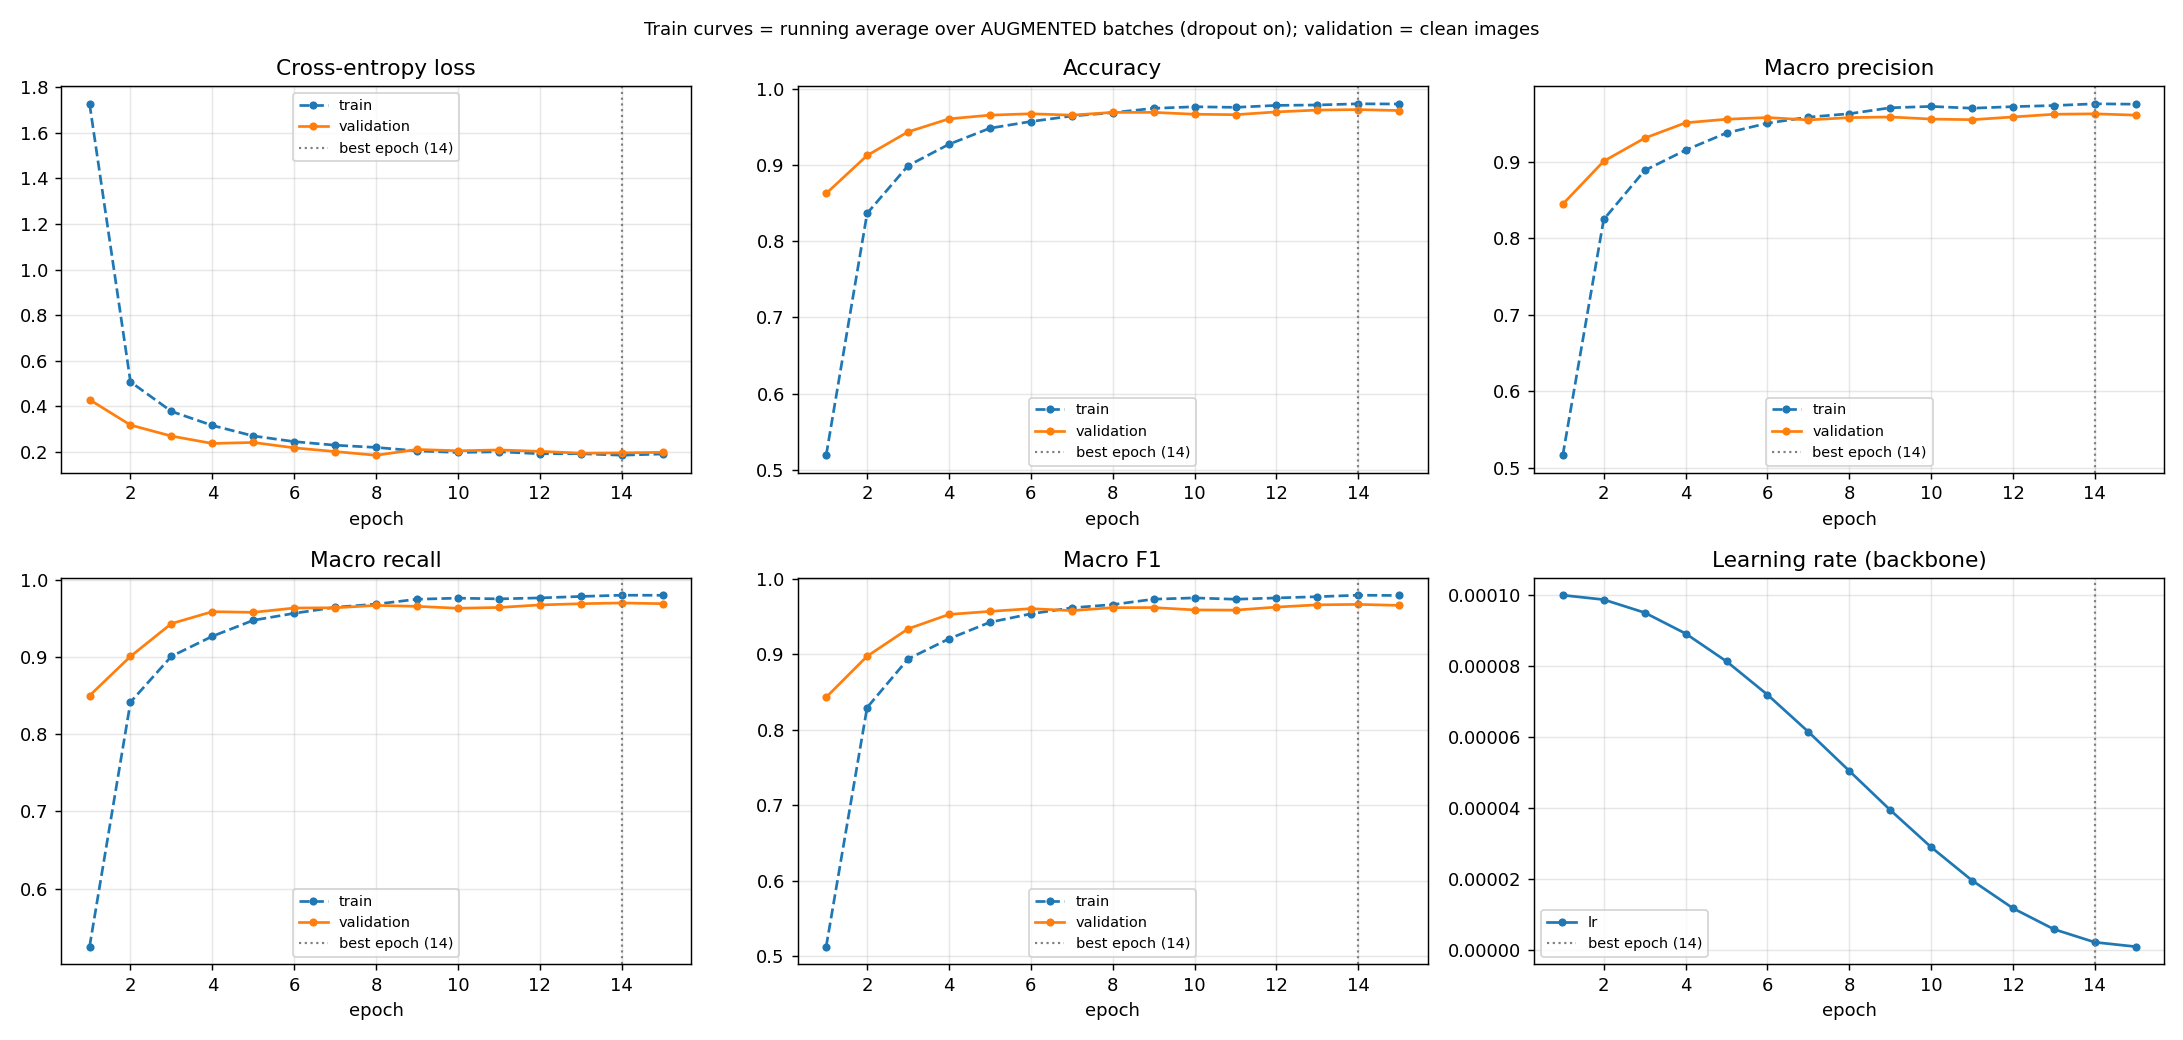


CONFUSION MATRIX - TEST (pooled PlantVillage + PlantDoc)


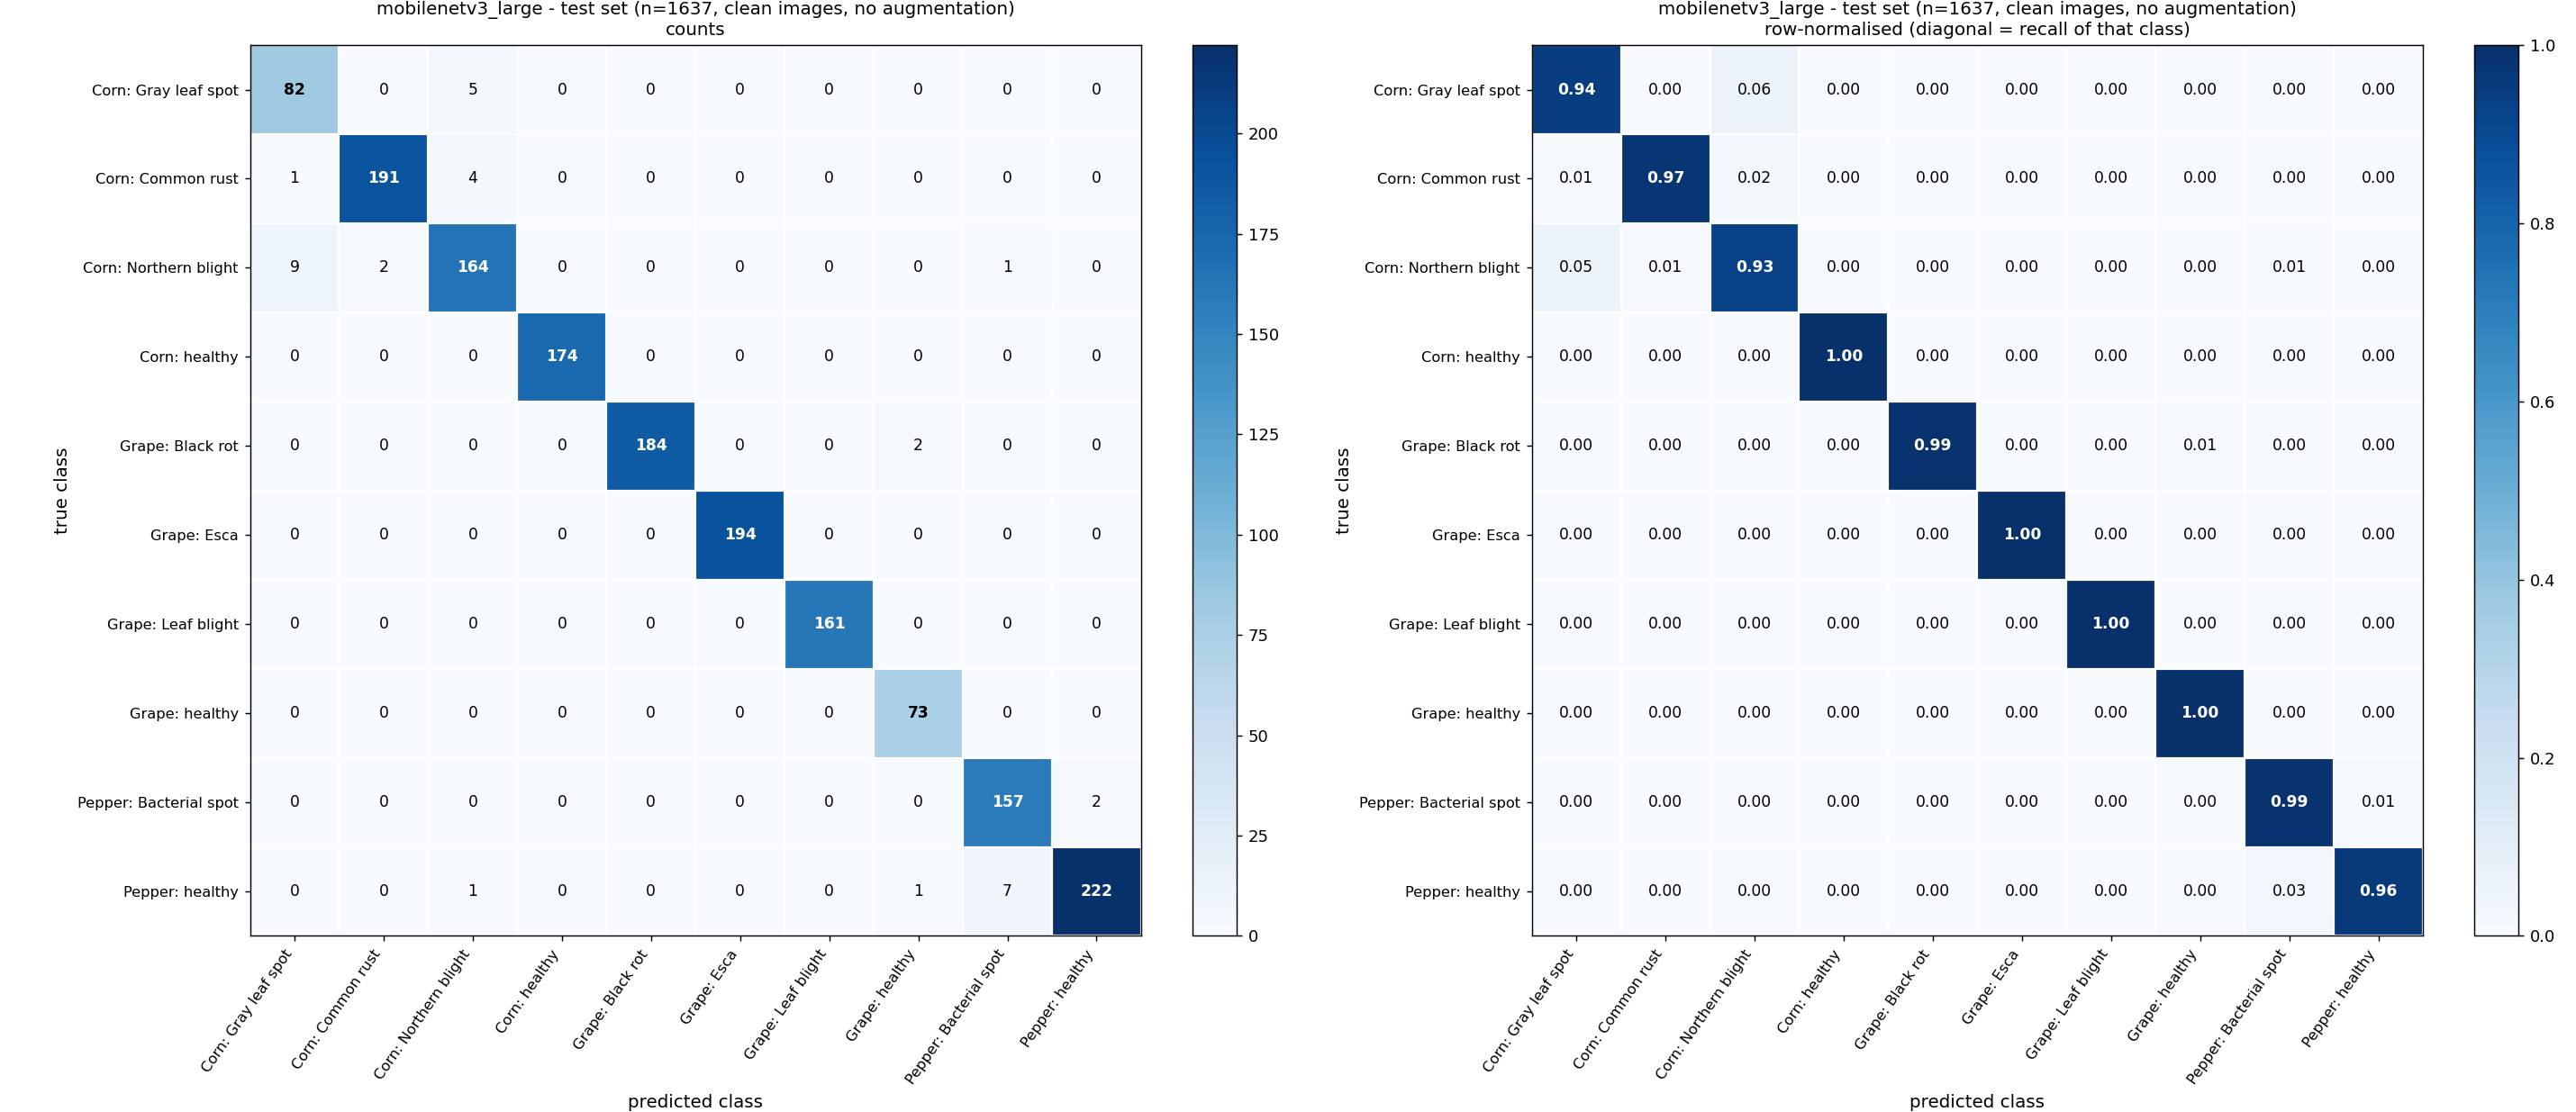


CONFUSION MATRIX - VALIDATION


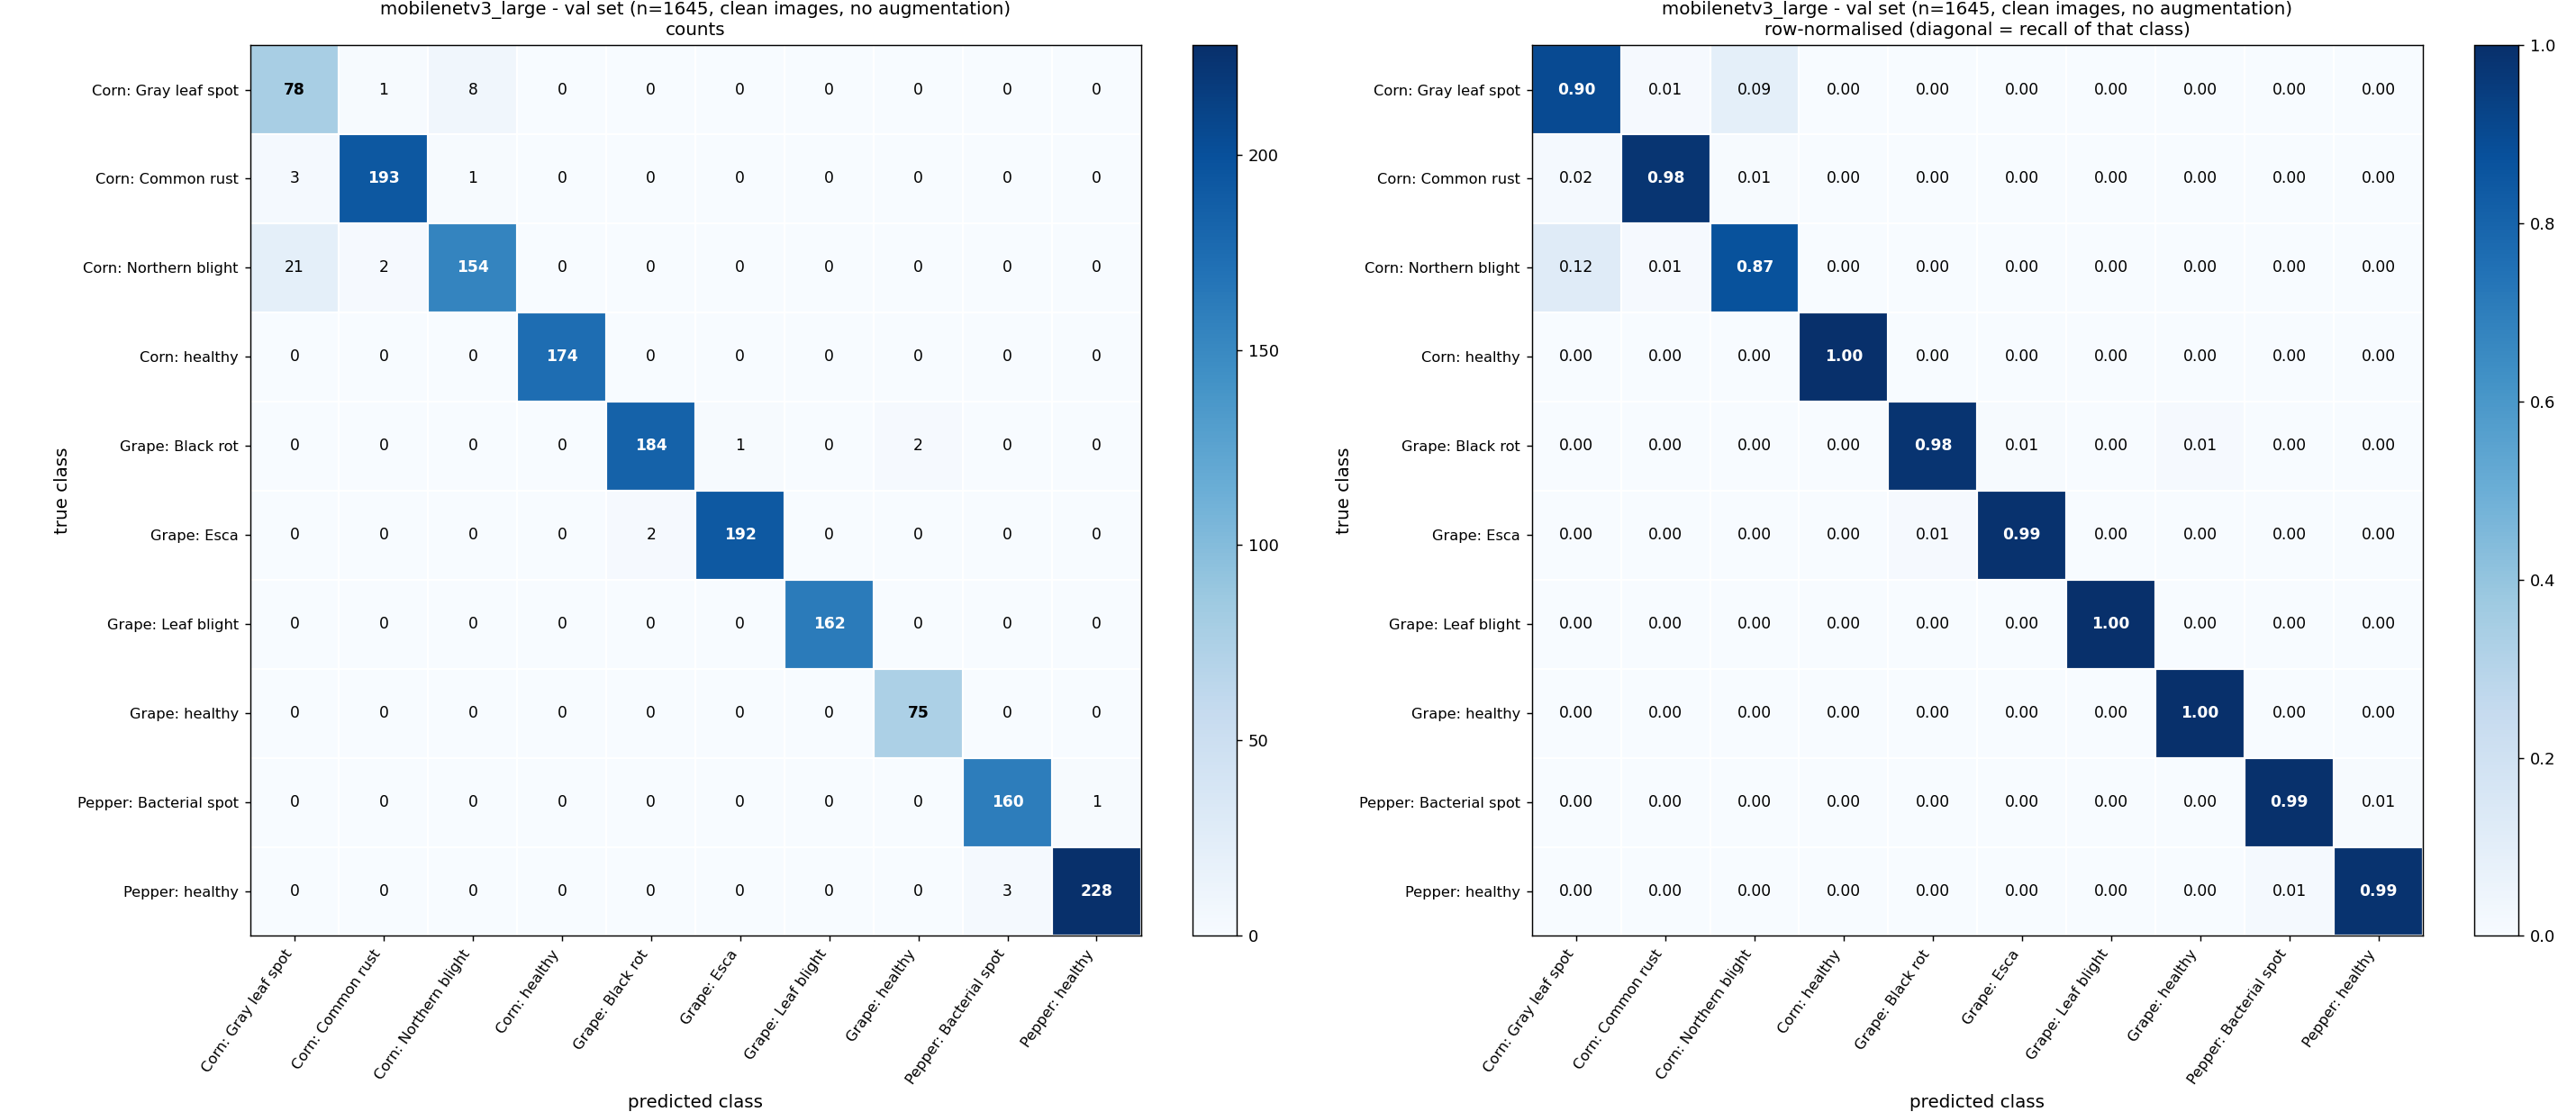


CONFUSION MATRIX - TRAIN


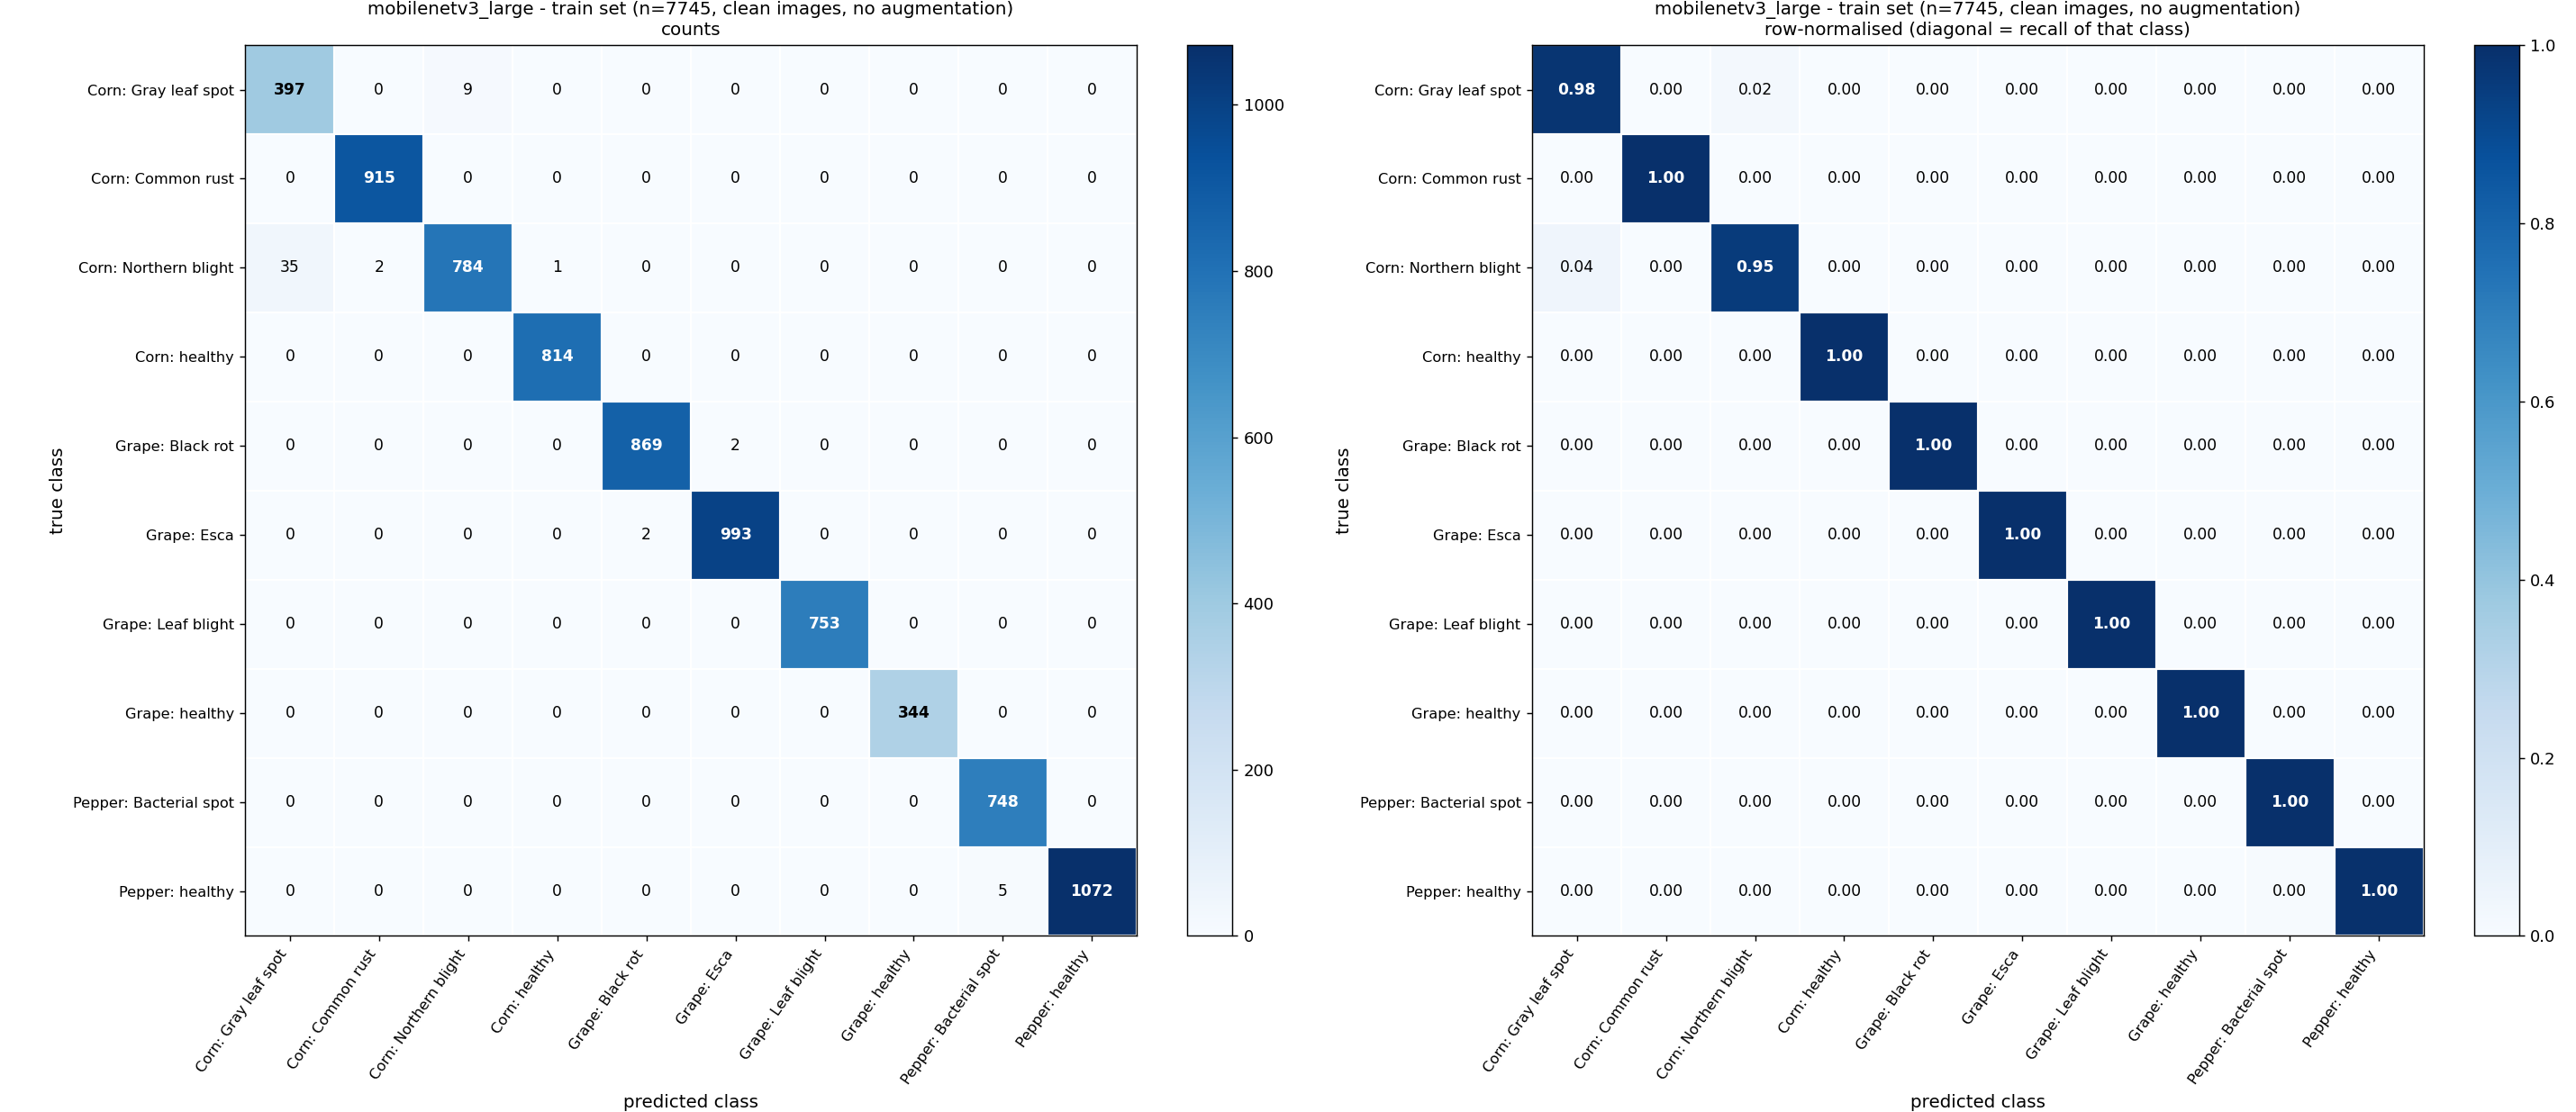


ROC curves - TEST


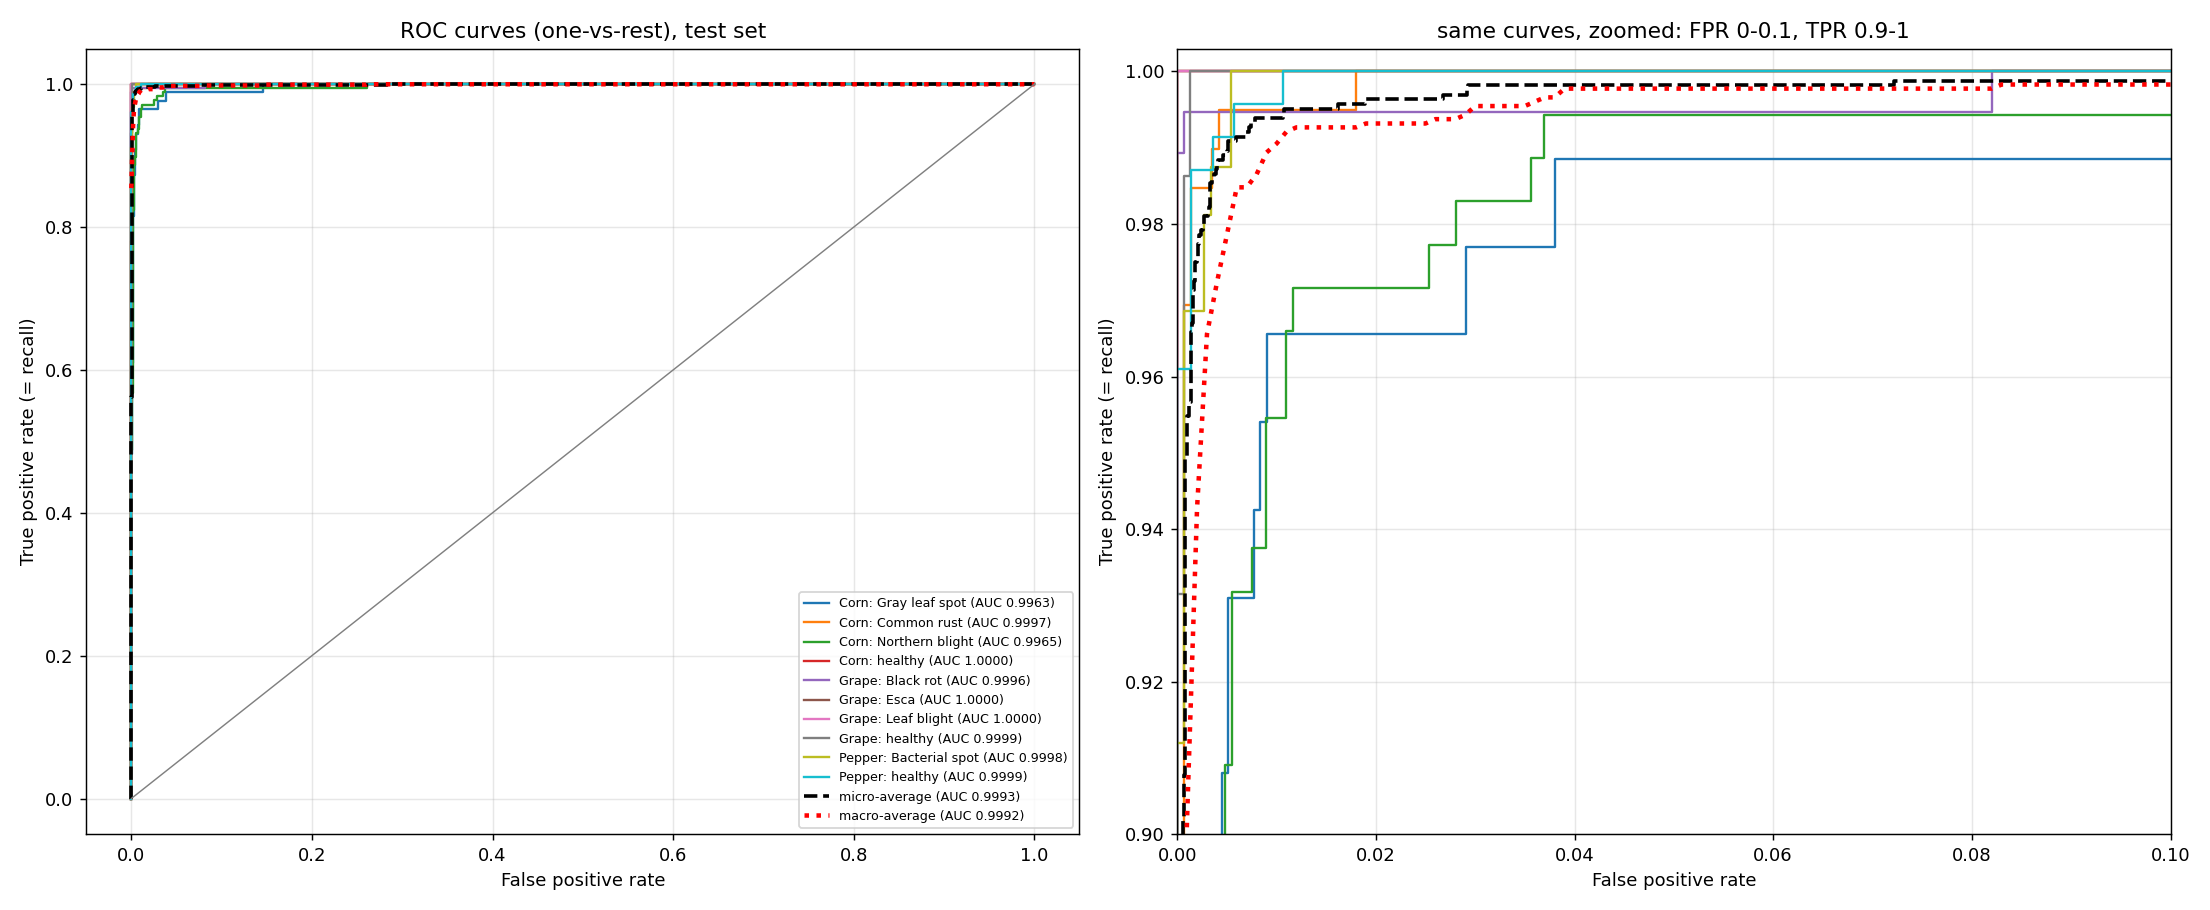


ROC curves - VALIDATION


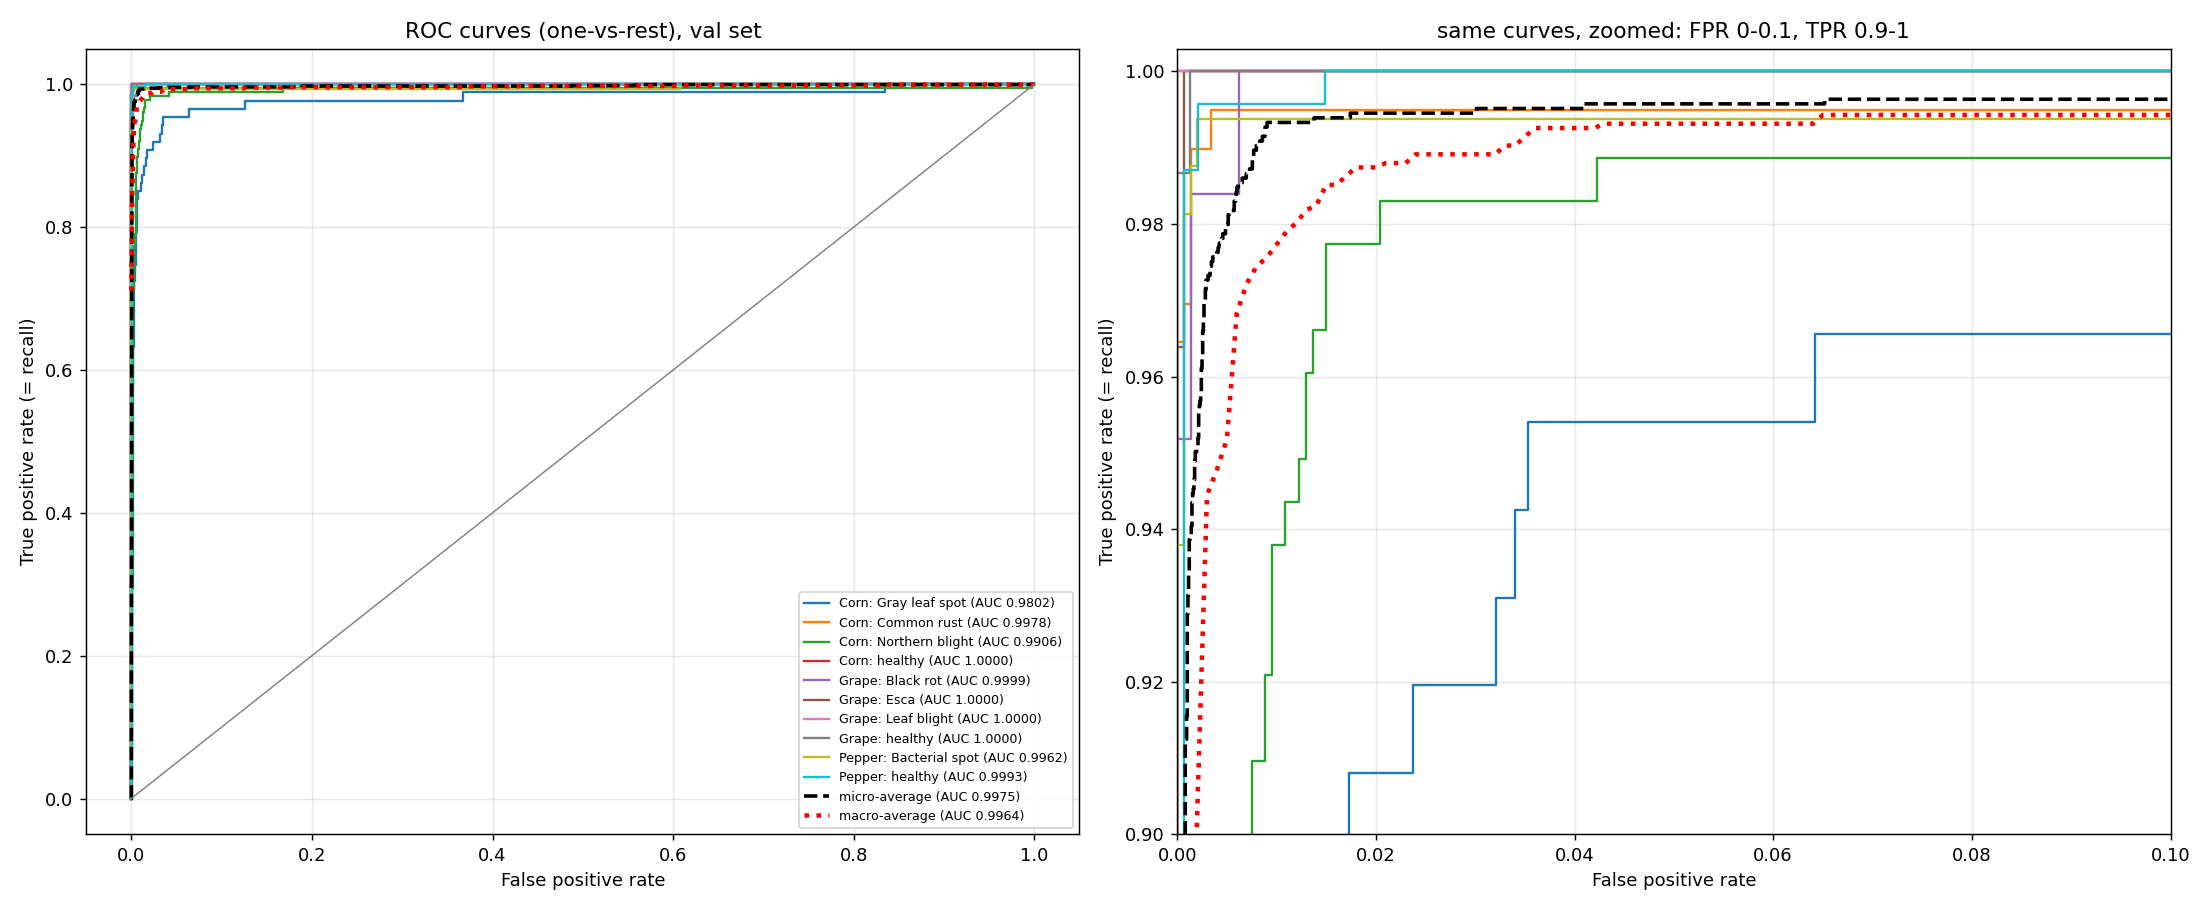


ROC curves - TRAIN


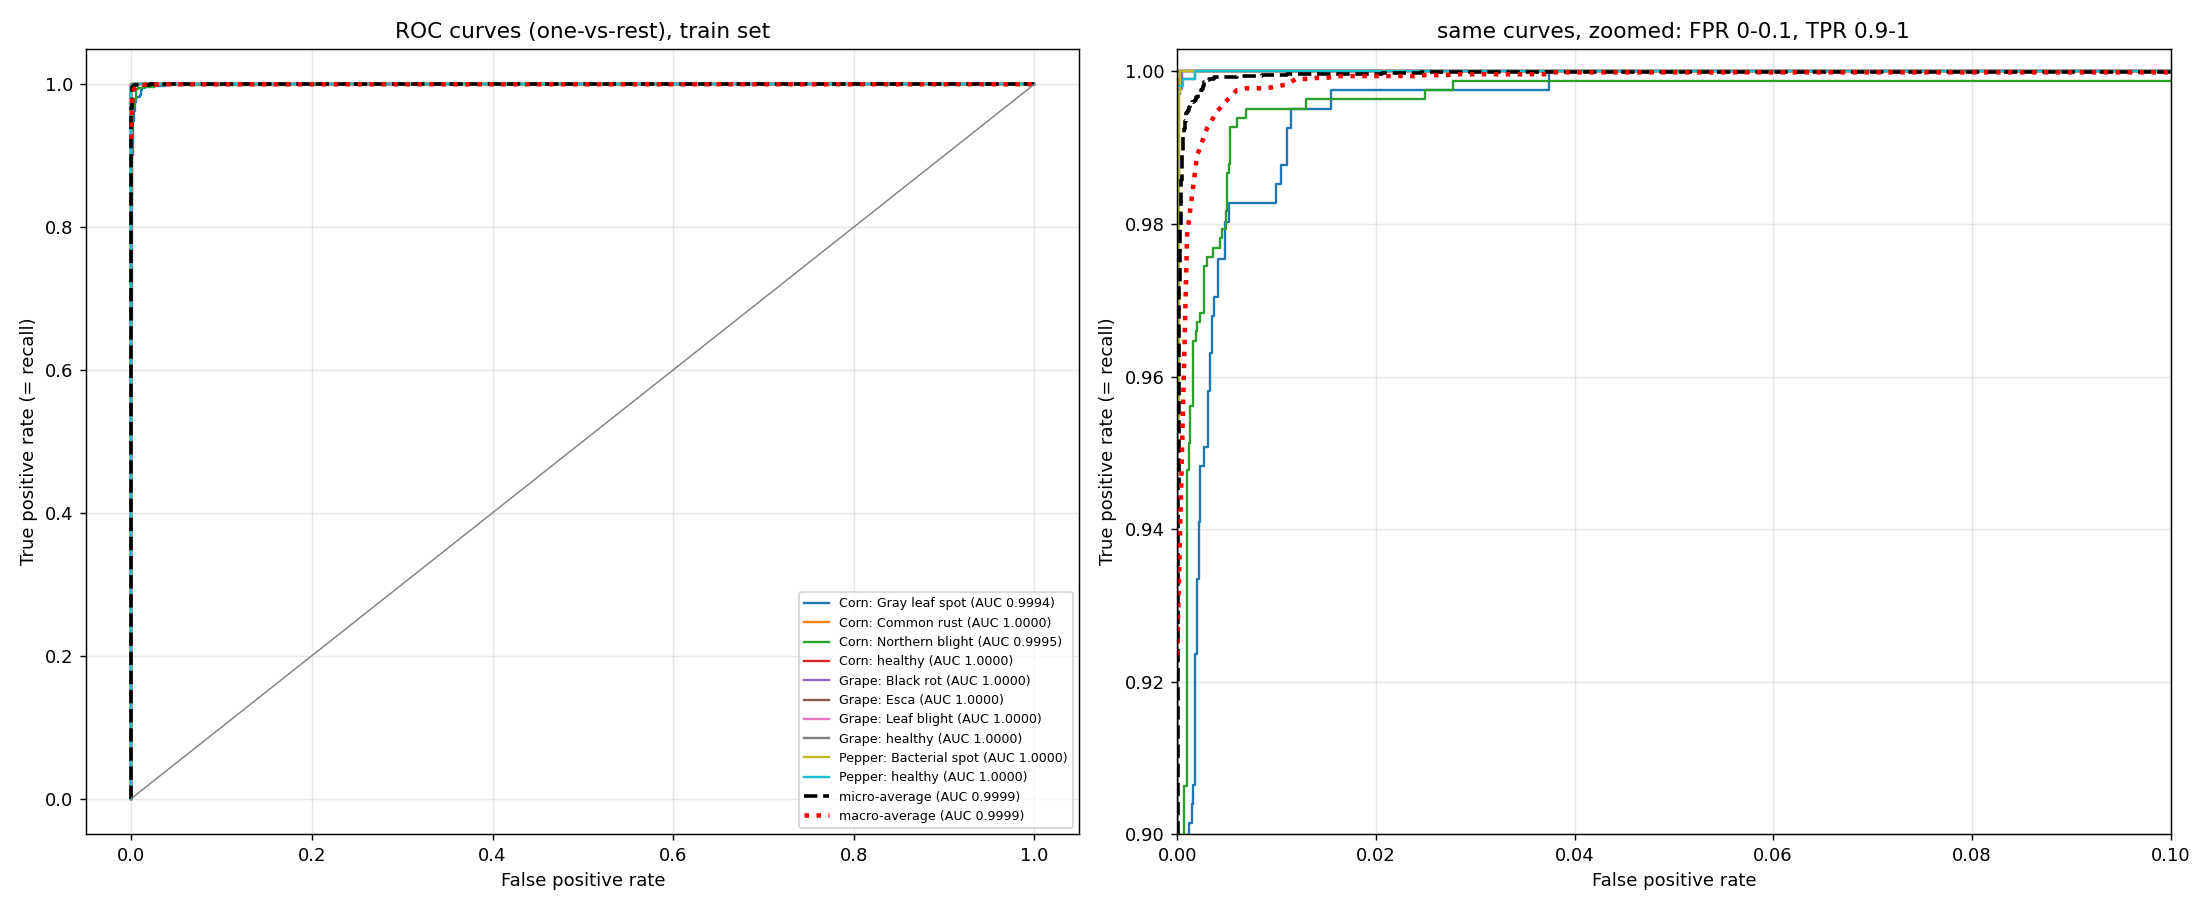


Per-class precision / recall / F1 - TEST


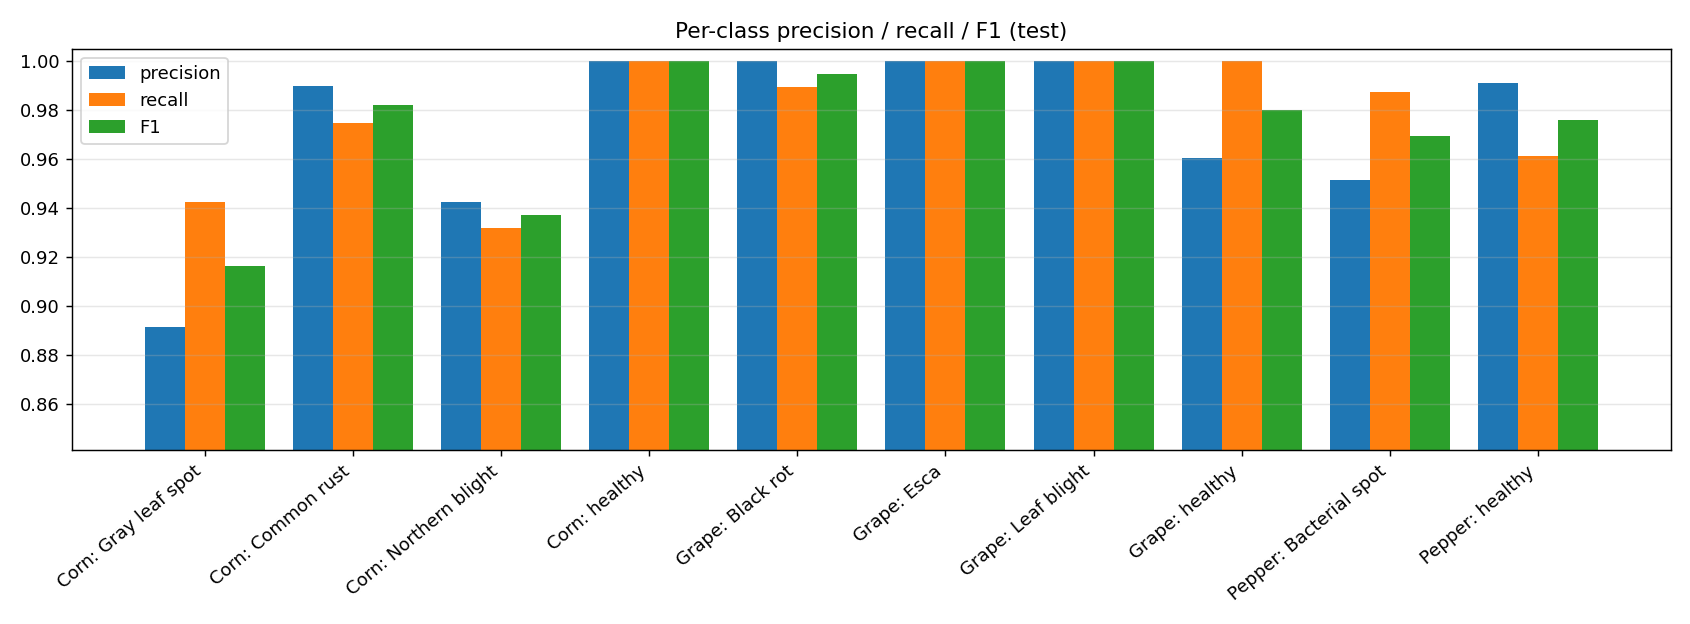


Calibration - TEST


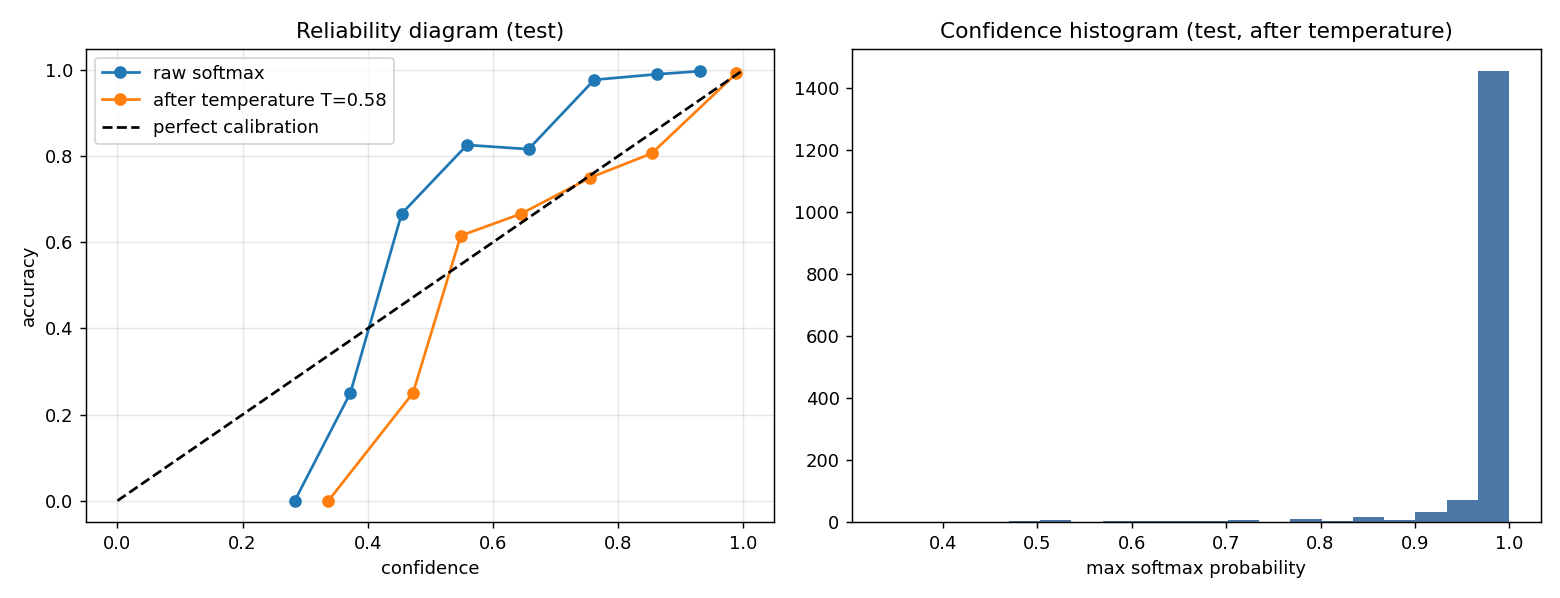


All files saved in /content/drive/MyDrive/plant-disease-v3/results/mobilenetv3_large/
['calibration_test.png', 'confusion_matrix_test.csv', 'confusion_matrix_test.png', 'confusion_matrix_train.csv', 'confusion_matrix_train.png', 'confusion_matrix_val.csv', 'confusion_matrix_val.png', 'full_report.txt', 'history.csv', 'metrics_summary.json', 'per_class_metrics.csv', 'per_class_metrics_test.png', 'roc_auc_per_class.csv', 'roc_test.png', 'roc_test_macro.npz', 'roc_train.png', 'roc_train_macro.npz', 'roc_val.png', 'roc_val_macro.npz', 'training_curves.png']


In [ ]:
import os, json, pandas as pd
from IPython.display import Image, display
OUT = f"/content/drive/MyDrive/plant-disease-v3/results/{MODEL}/"
s = json.load(open(OUT + "metrics_summary.json"))
print("Overall metrics (clean images, no augmentation):"); display(pd.DataFrame(s["splits"]).T.round(4))
for title, f in [("TRAIN vs VALIDATION per epoch: loss, accuracy, precision, recall, F1, learning rate", "training_curves.png"),
                 ("CONFUSION MATRIX - TEST (pooled PlantVillage + PlantDoc)", "confusion_matrix_test.png"),
                 ("CONFUSION MATRIX - VALIDATION", "confusion_matrix_val.png"), ("CONFUSION MATRIX - TRAIN", "confusion_matrix_train.png"),
                 ("ROC curves - TEST", "roc_test.png"), ("ROC curves - VALIDATION", "roc_val.png"), ("ROC curves - TRAIN", "roc_train.png"),
                 ("Per-class precision / recall / F1 - TEST", "per_class_metrics_test.png"), ("Calibration - TEST", "calibration_test.png")]:
    print("\n" + title); display(Image(OUT + f))
print("\nAll files saved in", OUT); print(sorted(os.listdir(OUT)))